In [ ]:
from google.colab import drive
#from google.colab import drive
#drive.flush_and_unmount()
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
pip install shap

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 540.5/540.5 kB 7.2 MB/s eta 0:00:00


In [ ]:
import matplotlib.pyplot as plt
from skimage import io
from skimage import color
from skimage.transform import resize
import math
from skimage.feature import hog
import numpy as np
import cv2
import os
import shap

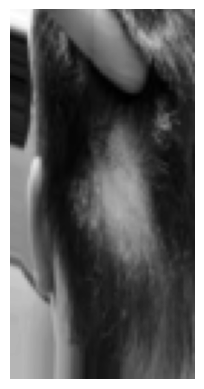

In [ ]:
img = resize(color.rgb2gray(io.imread("/content/drive/My Drive/HairDetection/Dataset/Training/Alopecia Areata/alopecia_areata_1195.jpg")), (128, 64))
#plt.figure(figsize=(15, 8))
plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()

In [ ]:
def CRSHOG(grayImg):
  mag = []
  theta = []
  for x in range(128):
    magnitudeArray = []
    angleArray = []
    for y in range(64):
      corners=[]
      rhombus=[]
      if(x-1>=0 and x+1<128 and x+2<128 and y-1>=0 and y+1<64 and y+2<64):
        corners.append(grayImg[x-1][y-1])  # Top Left Corner

        corners.append(grayImg[x-1][y+2])  # Top Right Corner
        corners.append(grayImg[x+2][y-1])  # Bottom left Corner
        corners.append(grayImg[x+2][y+2])  # Bottom Right Corner

        rhombus.append(grayImg[x][y-1])    #left
        rhombus.append(grayImg[x-1][y])    #Top
        rhombus.append(grayImg[x-1][y+1])  #Adjacent Top
        rhombus.append(grayImg[x][y+2])    #Right
        rhombus.append(grayImg[x+1][y+2])  #Adjacent Right
        rhombus.append(grayImg[x+2][y+1])  #Adjacent Bottom
        rhombus.append(grayImg[x+2][y])    #Bottom
        rhombus.append(grayImg[x+1][y-1])  #Adjacent left
      else:
        corners.append(0)  # Top Left Corner

        corners.append(0)  # Top Right Corner
        corners.append(0)  # Bottom left Corner
        corners.append(0)  # Bottom Right Corner

        rhombus.append(0)    #left
        rhombus.append(0)    #Top
        rhombus.append(0)  #Adjacent Top
        rhombus.append(0)    #Right
        rhombus.append(0)  #Adjacent Right
        rhombus.append(0)  #Adjacent Bottom
        rhombus.append(0)    #Bottom
        rhombus.append(0)  #Adjacent left
      topCornersMean=(corners[0] + corners[1])/2
      bottomCornersMean=(corners[2] + corners[3])/2
      gyCorners=topCornersMean-bottomCornersMean

      leftCornersMean=(corners[0] + corners[2])/2
      rightCornersMean=(corners[1] + corners[3])/2
      gxCorners=leftCornersMean-rightCornersMean




      topRhombusMean=(rhombus[1] + rhombus[2])/2
      bottomRhombusMean=(rhombus[5] + rhombus[6])/2
      gyRhombus=topRhombusMean-bottomRhombusMean

      leftRhombusMean=(rhombus[0] + rhombus[7])/2
      rightRhombusMean=(rhombus[3] + rhombus[4])/2

      gxRhombus=leftRhombusMean-rightRhombusMean

      gx=(gxCorners + gxRhombus)/2
      gy=(gyCorners + gyRhombus)/2

      magnitude = math.sqrt(pow(gx, 2) + pow(gy, 2))
      magnitudeArray.append(round(magnitude, 9))
      # Calculating angle
      if gx == 0:
        angle = math.degrees(0.0)
      else:
        angle = math.degrees(abs(math.atan(gy / gx)))
      angleArray.append(round(angle, 9))
    mag.append(magnitudeArray)
    theta.append(angleArray)
  return mag,theta


In [ ]:
img = np.array(img)
mag,theta=CRSHOG(img)


128


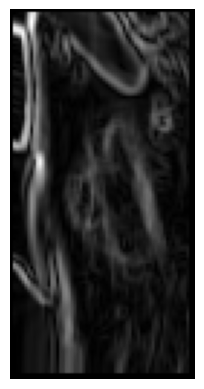

In [ ]:
mag = np.array(mag)
print(len(mag))
theta = np.array(theta)
#plt.figure(figsize=(15, 8))
plt.imshow(mag, cmap="gray")
plt.axis("off")
plt.show()

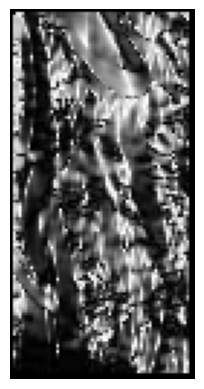

In [ ]:
#print(theta)
#plt.figure(figsize=(15, 8))
plt.imshow(theta, cmap="gray")
plt.axis("off")
plt.show()

In [ ]:
number_of_bins = 9
step_size = 180 / number_of_bins

In [ ]:
def calculate_j(angle):
  temp = (angle / step_size) - 0.5
  j = math.floor(temp)
  return j

In [ ]:
def calculate_Cj(j):
  Cj = step_size * (j + 0.5)
  return round(Cj, 9)

In [ ]:
def calculate_value_j(magnitude, angle, j):
  Cj = calculate_Cj(j+1)
  Vj = magnitude * ((Cj - angle) / step_size)
  return round(Vj, 9)

In [ ]:
histogram_points_nine = []
for i in range(0, 128, 8):
  temp = []
  for j in range(0, 64, 8):
    magnitude_values = [[mag[i][x] for x in range(j, j+8)] for i in range(i,i+8)]
    angle_values = [[theta[i][x] for x in range(j, j+8)] for i in range(i, i+8)]
    for k in range(len(magnitude_values)):
      for l in range(len(magnitude_values[0])):
        bins = [0.0 for _ in range(number_of_bins)]
        value_j = calculate_j(angle_values[k][l])
        Vj = calculate_value_j(magnitude_values[k][l], angle_values[k][l], value_j)
        Vj_1 = magnitude_values[k][l] - Vj
        bins[value_j]+=Vj
        bins[value_j+1]+=Vj_1
        bins = [round(x, 9) for x in bins]
    temp.append(bins)
  histogram_points_nine.append(temp)

In [ ]:
print(len(histogram_points_nine))
print(len(histogram_points_nine[0]))
print(len(histogram_points_nine[0][0]))

16
8
9


In [ ]:
epsilon = 1e-05

feature_vectors = []
for i in range(0, len(histogram_points_nine) - 1, 1):
  temp = []
  for j in range(0, len(histogram_points_nine[0]) - 1, 1):
    values = [[histogram_points_nine[i][x] for x in range(j, j+2)] for i in range(i, i+2)]
    final_vector = []
    for k in values:
      for l in k:
        for m in l:
          final_vector.append(m)
    k = round(math.sqrt(sum([pow(x, 2) for x in final_vector])), 9)
    final_vector = [round(x/(k + epsilon), 9) for x in final_vector]
    temp.append(final_vector)
  feature_vectors.append(temp)

In [ ]:
print(len(feature_vectors))
print(len(feature_vectors[0]))
print(len(feature_vectors[0][0]))

15
7
36


In [ ]:
print(feature_vectors)

[[[0.854119397, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.411249276, 0.008893786, 0.155421095, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.13896251, 0.007205668, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.195760984, 0.139251813, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.023471031, 0.41016204, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.109943295, 0.132566992, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.516620504, 0.367490702, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.631945204, 0.011806401, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.117075947, 0.141167374, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.540967077, 0.084875277, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.672943116, 0.01257235, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.460990352, 0.02951939, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.646873155, 0.10149146, 0.0, 0.0, 0.0, 0.0, 0.0, 0.282533479, 0.263109226, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.551239246, 0.035298452, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.324827435, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.106928865], [0.148162598, 0.137

In [ ]:
#import mahotas
from keras.preprocessing import image
from keras.applications.vgg16 import VGG16
from keras.applications.resnet50 import ResNet50
from keras.applications.resnet50 import preprocess_input
import numpy as np
import tensorflow as tf
from keras.models import Sequential
data_path = "/content/drive/My Drive/HairDetection/Derm-Figaro1K/"
x_image = []
y_label = []
#thresh = 0.4
labels = os.listdir(data_path)

for dirname in labels:

  #i=1
  print("Extracting..." + dirname)
  filepath = os.path.join(data_path, dirname)
  for file in os.listdir(filepath):
    #if(i>100):
    #  break
    #i=i+1
    #model = VGG16(weights='imagenet', include_top=False)
    #model.summary()
    filename=os.path.join(filepath, file)

    #image = cv2.imread(filename)
    #image=cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    img = resize(color.rgb2gray(io.imread(filename)), (128, 64))
    imgArray = np.array(img)

    mag,theta=CRSHOG(imgArray)
    mag = np.array(mag)
    #print(mag)
    theta = np.array(theta)
    #print(theta)
    #plt.figure(figsize=(15, 8))
    #plt.imshow(theta, cmap="gray")
    #plt.axis("off")
    #plt.show()
    histogram_points_nine = []
    for i in range(0, 128, 8):
      temp = []
      for j in range(0, 64, 8):
        magnitude_values = [[mag[i][x] for x in range(j, j+8)] for i in range(i,i+8)]
        angle_values = [[theta[i][x] for x in range(j, j+8)] for i in range(i, i+8)]
        for k in range(len(magnitude_values)):
          for l in range(len(magnitude_values[0])):
            bins = [0.0 for _ in range(number_of_bins)]
            value_j = calculate_j(angle_values[k][l])
            Vj = calculate_value_j(magnitude_values[k][l], angle_values[k][l], value_j)
            Vj_1 = magnitude_values[k][l] - Vj
            bins[value_j]+=Vj
            bins[value_j+1]+=Vj_1
            bins = [round(x, 9) for x in bins]
        temp.append(bins)
      histogram_points_nine.append(temp)
    epsilon = 1e-05

    feature_vectors = []
    for i in range(0, len(histogram_points_nine) - 1, 1):
      temp = []
      for j in range(0, len(histogram_points_nine[0]) - 1, 1):
        values = [[histogram_points_nine[i][x] for x in range(j, j+2)] for i in range(i, i+2)]
        final_vector = []
        for k in values:
          for l in k:
            for m in l:
              final_vector.append(m)
        k = round(math.sqrt(sum([pow(x, 2) for x in final_vector])), 9)
        final_vector = [round(x/(k + epsilon), 9) for x in final_vector]
        temp.append(final_vector)
      feature_vectors.append(temp)
    #image_hu = cv2.HuMoments(cv2.moments(image))
    #image_har = mahotas.features.haralick(image).mean(axis=0)
    resnetImage = image.load_img(filename, target_size=(256, 256))
    #resnetImage=resize(img,(256,256))
    #print(resnetImage.shape)
    imgdata = image.img_to_array(resnetImage)
    imgdata = np.expand_dims(imgdata, axis=0)
    imgdata = preprocess_input(imgdata)
    #print("Extracting VGG16 Features")
    #vgg16_feature = model.predict(imgdata)

    resnetModel = ResNet50(weights='imagenet', include_top=False)
    #resnetModel.summary()
    print("Extracting Resnet50 Features")
    resnet_feature=resnetModel.predict(imgdata)
    f_vector_concat = np.hstack([np.array(feature_vectors).flatten(),resnet_feature.flatten()])
    x_image.append(f_vector_concat)

    y_label.append(dirname)
  print(dirname,"ok!")


Extracting...Alopecia Areata
94765736/94765736 [==============================] - 1s 0us/step
Extracting Resnet50 Features
1/1 [==============================] - 2s 2s/step
Extracting Resnet50 Features
1/1 [==============================] - 3s 3s/step
Extracting Resnet50 Features
1/1 [==============================] - 2s 2s/step
Extracting Resnet50 Features
1/1 [==============================] - 3s 3s/step
Extracting Resnet50 Features


1/1 [==============================] - 1s 1s/step
Extracting Resnet50 Features


1/1 [==============================] - 4s 4s/step
Extracting Resnet50 Features
1/1 [==============================] - 2s 2s/step
Extracting Resnet50 Features
1/1 [==============================] - 3s 3s/step
Extracting Resnet50 Features
1/1 [==============================] - 2s 2s/step
Extracting Resnet50 Features
1/1 [==============================] - 3s 3s/step
Extracting Resnet50 Features
1/1 [==============================] - 3s 3s/step
Extracting Resnet50 Features
1/1 [==============================] - 3s 3s/step
Extracting Resnet50 Features
1/1 [==============================] - 1s 1s/step
Extracting Resnet50 Features
1/1 [==============================] - 4s 4s/step
Extracting Resnet50 Features
1/1 [==============================] - 2s 2s/step
Extracting Resnet50 Features
1/1 [==============================] - 3s 3s/step
Extracting Resnet50 Features
1/1 [==============================] - 1s 1s/step
Extracting Resnet50 Features
1/1 [==============================] - 2s 2s/step
Ex

In [ ]:
import pickle
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, BatchNormalization, Activation
#from keras.layers.convolutional import Conv2D, MaxPooling2D
#from keras.constraints import maxnorm
#from keras.utils import np_utils
#seed = 21
#print(x_image.count)
x_image_n = np.array(x_image)
y_label_n = np.array(y_label)
pickle_out = open("/content/drive/My Drive/HairDetection/XDermCRSHOG.pickle","wb")
pickle.dump(x_image_n, pickle_out)
pickle_out.close()

pickle_out = open("/content/drive/My Drive/HairDetection/yDermCRSHOG.pickle","wb")
pickle.dump(y_label_n, pickle_out)
pickle_out.close()

In [ ]:
import pickle
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split as data_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import r2_score, mean_squared_error, confusion_matrix, precision_score, recall_score, accuracy_score, f1_score
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.svm import SVC
from skimage import feature
from sklearn.decomposition import PCA
x_image = pickle.load(open("/content/drive/My Drive/HairDetection/XDermCRSHOG.pickle", "rb"))
y_label=pickle.load(open("/content/drive/My Drive/HairDetection/yDermCRSHOG.pickle", "rb"))
x_image_n = np.array(x_image)
y_label_n = np.array(y_label)
#x_image_features = np.vstack(np.array(x_image_n))
# feature scaling between 0-1
#scaler = MinMaxScaler(feature_range=(0, 1))
scaler = StandardScaler()
x_image_scaled = scaler.fit_transform(x_image_n)
#pca1=PCA(n_components=4)
#feature_scaled_pca=pca1.transform(x_image_scaled)
#split data set
#x_train, x_test, y_train, y_test = data_split(x_image_scaled, y_label_n, test_size=0.3)
x_train, x_test, y_train, y_test = data_split(x_image_scaled, y_label_n, test_size=0.3)
pca1=PCA(n_components=4)
x_train=pca1.fit_transform(x_train)
x_test=pca1.transform(x_test)
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

                 precision    recall  f1-score   support

Alopecia Areata     0.9903    0.9968    0.9935       308
        Healthy     0.9957    0.9872    0.9914       234

       accuracy                         0.9926       542
      macro avg     0.9930    0.9920    0.9925       542
   weighted avg     0.9926    0.9926    0.9926       542



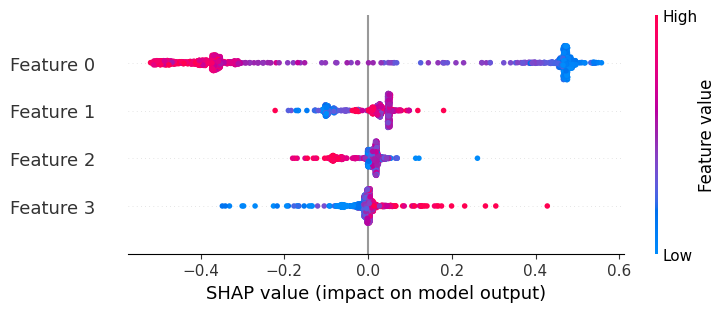

In [ ]:
#train the model
clf_rfc = RandomForestClassifier().fit(x_train, y_train)
#clf_rfc = RandomForestClassifier().fit(feature_scaled_pca, y_train)
#save the model
filename = '/content/drive/My Drive/HairDetection/CRSHOGDerm_modelRF.sav'
pickle.dump(clf_rfc, open(filename, 'wb'))
#Load Data From Model------------------------------------------------------------------
loaded_model = pickle.load(open(filename, 'rb'))
# evaluate the model
y_pred_rfc = clf_rfc.predict(x_test)

# 0.5576923076923077
#print("Precision= ",precision_score(y_test, y_pred_rfc, average='weighted', labels=np.unique(y_pred_rfc)))
# 0.5858423061196674
print(classification_report(y_test, y_pred_rfc,digits=4))

# 0.5648969666761506
#print(r2_score(y_test, y_pred_rfc))
explainer = shap.TreeExplainer(clf_rfc)
sv = explainer(x_train)

#shap_values = explanation.values
# make sure the SHAP values add up to marginal predictions
#np.abs(shap_values.sum(axis=1) + explanation.base_values - y_pred_rfc).max()
shap.plots.beeswarm(sv[:,:,1])

In [ ]:
from matplotlib.ticker import PercentFormatter
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import pandas as pd

def cm_analysis(y_true, y_pred, filename, labels, classes, ymap=None, figsize=(8,5)):
    """
    Generate matrix plot of confusion matrix with pretty annotations.
    The plot image is saved to disk.
    args:
      y_true:    true label of the data, with shape (nsamples,)
      y_pred:    prediction of the data, with shape (nsamples,)
      filename:  filename of figure file to save
      labels:    string array, name the order of class labels in the confusion matrix.
                 use `clf.classes_` if using scikit-learn models.
                 with shape (nclass,).
      classes:   aliases for the labels. String array to be shown in the cm plot.
      ymap:      dict: any -> string, length == nclass.
                 if not None, map the labels & ys to more understandable strings.
                 Caution: original y_true, y_pred and labels must align.
      figsize:   the size of the figure plotted.
    """
    sns.set(font_scale=1.5)

    if ymap is not None:
        y_pred = [ymap[yi] for yi in y_pred]
        y_true = [ymap[yi] for yi in y_true]
        labels = [ymap[yi] for yi in labels]
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    cm_sum = np.sum(cm, axis=1, keepdims=True)
    cm_perc = cm / cm_sum.astype(float) * 100
    annot = np.empty_like(cm).astype(str)
    nrows, ncols = cm.shape
    for i in range(nrows):
        for j in range(ncols):
            c = cm[i, j]
            p = cm_perc[i, j]
            if i == j:
                s = cm_sum[i]
                annot[i, j] = '%.2f%%' % (p)
            #elif c == 0:
            #    annot[i, j] = ''
            else:
                annot[i, j] = '%.2f%%' % (p)
    cm = confusion_matrix(y_true, y_pred, labels=labels, normalize='true')
    cm = pd.DataFrame(cm, index=labels, columns=labels)
    cm = cm * 100
    cm.index.name = 'True Label'
    cm.columns.name = 'Predicted Label'
    fig, ax = plt.subplots(figsize=figsize)
    plt.yticks(va='center')

    sns.heatmap(cm, annot=annot, fmt='', ax=ax, xticklabels=classes, cbar=True, cbar_kws={'format':PercentFormatter()}, yticklabels=classes, cmap="Blues")
    #plt.savefig(filename,  bbox_inches='tight')

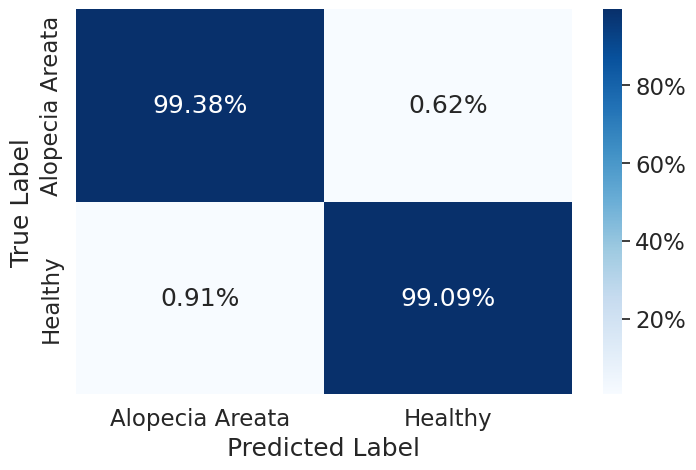

In [ ]:
labels=['Alopecia Areata','Healthy']
#cm=confusion_matrix(y_test, y_pred_rfc,labels=labels)
#print(cm)
cm_analysis(y_test,y_pred_rfc,"RFCM.jpg",labels,labels)

In [ ]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_rfc).ravel()

print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

# Sensitivity, hit rate, recall, or true positive rate
TPR = np.round(tp/(tp+fn),2)*100
# Specificity or true negative rate
TNR = np.round(tn/(tn+fp),2) * 100
# Precision or positive predictive value
PPV = tp/(tp+fp)
# Negative predictive value
NPV = tn/(tn+fn)
# Fall out or false positive rate
FPR = np.round(fp/(fp+tn),2)*100
# False negative rate
FNR = np.round(fn/(tp+fn),2)*100
# False discovery rate
FDR = fp/(tp+fp)

# Overall accuracy
ACC = (tp+tn)/(tp+fp+fn+tn)
print("True Positive Rate:", TPR)
print("True Negative Rate:", TNR)
print("False Positive Rate:", FPR)
print("False Negative Rate:", FNR)

True Negative: 321
False Positive: 2
False Negative: 2
True Positive: 217
True Positive Rate: 99.0
True Negative Rate: 99.0
False Positive Rate: 1.0
False Negative Rate: 1.0


                 precision    recall  f1-score   support

Alopecia Areata     0.9935    0.9935    0.9935       308
        Healthy     0.9915    0.9915    0.9915       234

       accuracy                         0.9926       542
      macro avg     0.9925    0.9925    0.9925       542
   weighted avg     0.9926    0.9926    0.9926       542



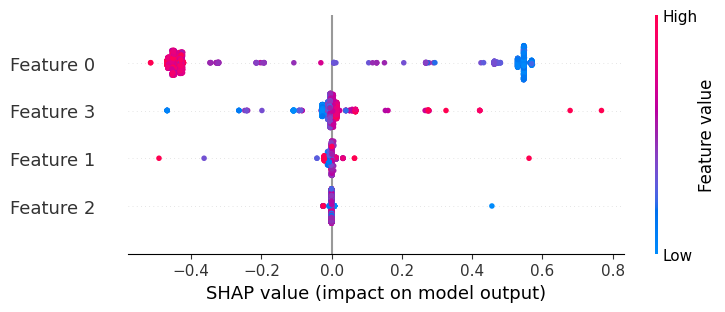

In [ ]:
from sklearn.tree import DecisionTreeClassifier
classifier = DecisionTreeClassifier()
model=classifier.fit(x_train, y_train)


filename = '/content/drive/My Drive/HairDetection/CRSHOGDerm_modelDT.sav'
pickle.dump(model, open(filename, 'wb'))
#Load Data From Model------------------------------------------------------------------
loaded_model = pickle.load(open(filename, 'rb'))
y_pred = model.predict(x_test)
from sklearn.metrics import classification_report, confusion_matrix
#print("Accuracy= ",accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred,digits=4))
explainer = shap.TreeExplainer(model)
sv = explainer(x_train)

#shap_values = explanation.values
# make sure the SHAP values add up to marginal predictions
#np.abs(shap_values.sum(axis=1) + explanation.base_values - y_pred_rfc).max()
shap.plots.beeswarm(sv[:,:,1])

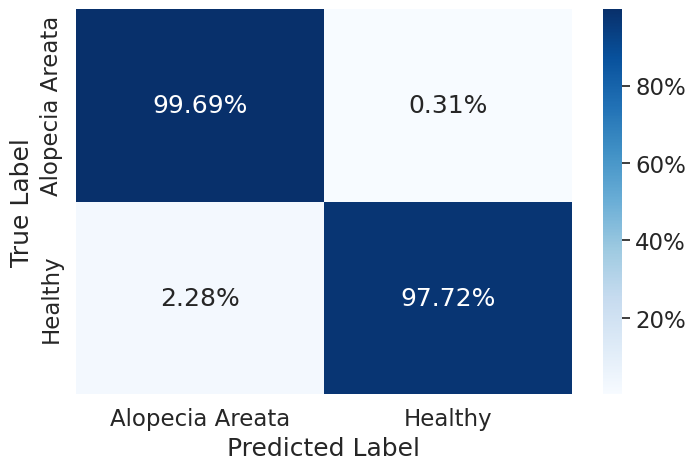

In [ ]:
#cm=confusion_matrix(y_test, y_pred,labels=labels)
#print(cm)
cm_analysis(y_test,y_pred,"DTCM.jpg",labels,labels)

In [ ]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

# Sensitivity, hit rate, recall, or true positive rate
TPR = np.round(tp/(tp+fn),2)*100
# Specificity or true negative rate
TNR = np.round(tn/(tn+fp),2) * 100
# Precision or positive predictive value
PPV = tp/(tp+fp)
# Negative predictive value
NPV = tn/(tn+fn)
# Fall out or false positive rate
FPR = np.round(fp/(fp+tn),2)*100
# False negative rate
FNR = np.round(fn/(tp+fn),2)*100
# False discovery rate
FDR = fp/(tp+fp)

# Overall accuracy
ACC = (tp+tn)/(tp+fp+fn+tn)
print("True Positive Rate:", TPR)
print("True Negative Rate:", TNR)
print("False Positive Rate:", FPR)
print("False Negative Rate:", FNR)

True Negative: 322
False Positive: 1
False Negative: 5
True Positive: 214
True Positive Rate: 98.0
True Negative Rate: 100.0
False Positive Rate: 0.0
False Negative Rate: 2.0


In [ ]:
from sklearn.svm import SVC
#x_image_n = np.array(x_image)
#y_label_n = np.array(y_label)
# feature scaling between 0-1
#scaler = MinMaxScaler(feature_range=(0, 1))
#x_image_scaled = scaler.fit_transform(x_image_n)

#split data set
#x_train, x_test, y_train, y_test = data_split(x_image_n, y_label_n, test_size=0.3)
clf_svc = SVC(kernel="linear").fit(x_train, y_train)
filename = '/content/drive/My Drive/HairDetection/CRSHOGDerm_modelSVM.sav'
pickle.dump(clf_svc, open(filename, 'wb'))
#Load Data From Model------------------------------------------------------------------
loaded_model = pickle.load(open(filename, 'rb'))
# evaluating model
y_pred_svc = clf_svc.predict(x_test)
print(classification_report(y_test, y_pred_svc,digits=4))


                 precision    recall  f1-score   support

Alopecia Areata     0.9968    1.0000    0.9984       308
        Healthy     1.0000    0.9957    0.9979       234

       accuracy                         0.9982       542
      macro avg     0.9984    0.9979    0.9981       542
   weighted avg     0.9982    0.9982    0.9982       542



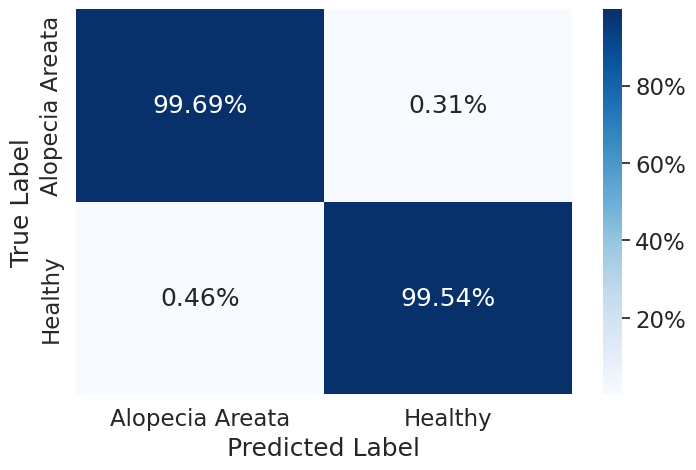

In [ ]:
#cm=confusion_matrix(y_test, y_pred_svc,labels=labels)
#print(cm)
cm_analysis(y_test,y_pred_svc,"SVMCM.jpg",labels,labels)

In [ ]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_svc).ravel()

print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

# Sensitivity, hit rate, recall, or true positive rate
TPR = np.round(tp/(tp+fn),2)*100
# Specificity or true negative rate
TNR = np.round(tn/(tn+fp),2) * 100
# Precision or positive predictive value
PPV = tp/(tp+fp)
# Negative predictive value
NPV = tn/(tn+fn)
# Fall out or false positive rate
FPR = np.round(fp/(fp+tn),2)*100
# False negative rate
FNR = np.round(fn/(tp+fn),2)*100
# False discovery rate
FDR = fp/(tp+fp)

# Overall accuracy
ACC = (tp+tn)/(tp+fp+fn+tn)
print("True Positive Rate:", TPR)
print("True Negative Rate:", TNR)
print("False Positive Rate:", FPR)
print("False Negative Rate:", FNR)

True Negative: 322
False Positive: 1
False Negative: 1
True Positive: 218
True Positive Rate: 100.0
True Negative Rate: 100.0
False Positive Rate: 0.0
False Negative Rate: 0.0


In [ ]:
from sklearn.naive_bayes import GaussianNB
gnb = GaussianNB()
filename = '/content/drive/My Drive/HairDetection/CRSHOGDerm_modelNB.sav'

modelNB = gnb.fit(x_train, y_train)
y_predNB=modelNB.predict(x_test)
pickle.dump(modelNB, open(filename, 'wb'))
#Load Data From Model------------------------------------------------------------------
loaded_model = pickle.load(open(filename, 'rb'))
print(classification_report(y_test, y_predNB,digits=4))

                 precision    recall  f1-score   support

Alopecia Areata     0.9806    0.9870    0.9838       308
        Healthy     0.9828    0.9744    0.9785       234

       accuracy                         0.9815       542
      macro avg     0.9817    0.9807    0.9812       542
   weighted avg     0.9816    0.9815    0.9815       542



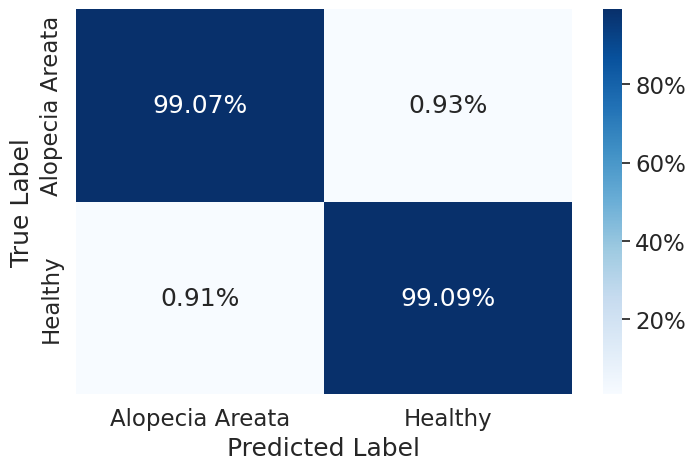

In [ ]:
#cm=confusion_matrix(y_test, y_predNB,labels=labels)
#print(cm)
cm_analysis(y_test,y_predNB,"NBCM.jpg",labels,labels)

In [ ]:
tn, fp, fn, tp = confusion_matrix(y_test, y_predNB).ravel()

print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

# Sensitivity, hit rate, recall, or true positive rate
TPR = np.round(tp/(tp+fn),2)*100
# Specificity or true negative rate
TNR = np.round(tn/(tn+fp),2) * 100
# Precision or positive predictive value
PPV = tp/(tp+fp)
# Negative predictive value
NPV = tn/(tn+fn)
# Fall out or false positive rate
FPR = np.round(fp/(fp+tn),2)*100
# False negative rate
FNR = np.round(fn/(tp+fn),2)*100
# False discovery rate
FDR = fp/(tp+fp)

# Overall accuracy
ACC = (tp+tn)/(tp+fp+fn+tn)
print("True Positive Rate:", TPR)
print("True Negative Rate:", TNR)
print("False Positive Rate:", FPR)
print("False Negative Rate:", FNR)

True Negative: 320
False Positive: 3
False Negative: 2
True Positive: 217
True Positive Rate: 99.0
True Negative Rate: 99.0
False Positive Rate: 1.0
False Negative Rate: 1.0


In [ ]:
from sklearn.linear_model import LogisticRegression
lr=LogisticRegression(random_state=1234)
filename = '/content/drive/My Drive/HairDetection/CRSHOGDerm_modelLR.sav'

modelLR = lr.fit(x_train, y_train)
y_predLR=modelLR.predict(x_test)
pickle.dump(modelLR, open(filename, 'wb'))
#Load Data From Model------------------------------------------------------------------
loaded_model = pickle.load(open(filename, 'rb'))
print(classification_report(y_test, y_predLR,digits=4))


                 precision    recall  f1-score   support

Alopecia Areata     0.9968    1.0000    0.9984       308
        Healthy     1.0000    0.9957    0.9979       234

       accuracy                         0.9982       542
      macro avg     0.9984    0.9979    0.9981       542
   weighted avg     0.9982    0.9982    0.9982       542



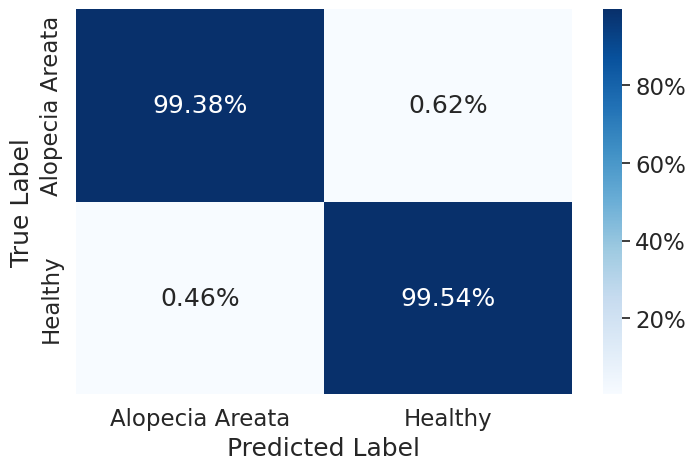

In [ ]:
#cm=confusion_matrix(y_test, y_predLR,labels=labels)
#print(cm)
cm_analysis(y_test,y_predLR,"LRCM.jpg",labels,labels)

In [ ]:
tn, fp, fn, tp = confusion_matrix(y_test, y_predLR).ravel()

print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

# Sensitivity, hit rate, recall, or true positive rate
TPR = np.round(tp/(tp+fn),2)*100
# Specificity or true negative rate
TNR = np.round(tn/(tn+fp),2) * 100
# Precision or positive predictive value
PPV = tp/(tp+fp)
# Negative predictive value
NPV = tn/(tn+fn)
# Fall out or false positive rate
FPR = np.round(fp/(fp+tn),2)*100
# False negative rate
FNR = np.round(fn/(tp+fn),2)*100
# False discovery rate
FDR = fp/(tp+fp)

# Overall accuracy
ACC = (tp+tn)/(tp+fp+fn+tn)
print("True Positive Rate:", TPR)
print("True Negative Rate:", TNR)
print("False Positive Rate:", FPR)
print("False Negative Rate:", FNR)

True Negative: 321
False Positive: 2
False Negative: 1
True Positive: 218
True Positive Rate: 100.0
True Negative Rate: 99.0
False Positive Rate: 1.0
False Negative Rate: 0.0


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier()
filename = '/content/drive/My Drive/HairDetection/CRSHOGDerm_modelKNN.sav'

modelKNN = knn.fit(x_train, y_train)
y_predknn=modelKNN.predict(x_test)
pickle.dump(modelKNN, open(filename, 'wb'))
#Load Data From Model------------------------------------------------------------------
loaded_model = pickle.load(open(filename, 'rb'))
print(classification_report(y_test, y_predknn,digits=4))

                 precision    recall  f1-score   support

Alopecia Areata     1.0000    1.0000    1.0000       308
        Healthy     1.0000    1.0000    1.0000       234

       accuracy                         1.0000       542
      macro avg     1.0000    1.0000    1.0000       542
   weighted avg     1.0000    1.0000    1.0000       542



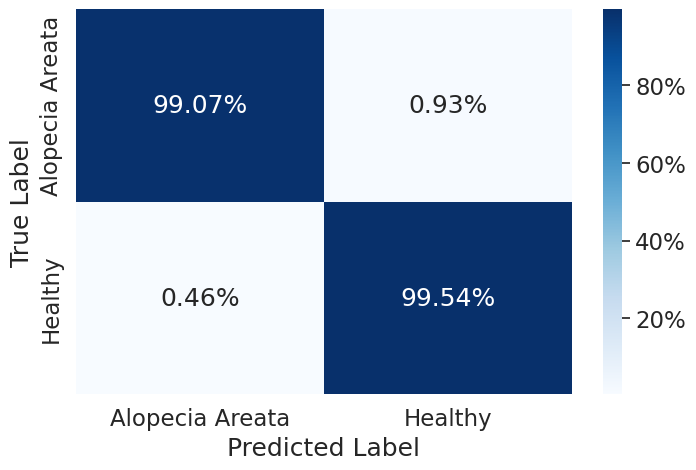

In [ ]:
#cm=confusion_matrix(y_test, y_predknn,labels=labels)
#print(cm)
cm_analysis(y_test,y_predknn,"KNNCM.jpg",labels,labels)

In [ ]:
tn, fp, fn, tp = confusion_matrix(y_test, y_predknn).ravel()

print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

# Sensitivity, hit rate, recall, or true positive rate
TPR = np.round(tp/(tp+fn),2)*100
# Specificity or true negative rate
TNR = np.round(tn/(tn+fp),2) * 100
# Precision or positive predictive value
PPV = tp/(tp+fp)
# Negative predictive value
NPV = tn/(tn+fn)
# Fall out or false positive rate
FPR = np.round(fp/(fp+tn),2)*100
# False negative rate
FNR = np.round(fn/(tp+fn),2)*100
# False discovery rate
FDR = fp/(tp+fp)

# Overall accuracy
ACC = (tp+tn)/(tp+fp+fn+tn)
print("True Positive Rate:", TPR)
print("True Negative Rate:", TNR)
print("False Positive Rate:", FPR)
print("False Negative Rate:", FNR)

True Negative: 320
False Positive: 3
False Negative: 1
True Positive: 218
True Positive Rate: 100.0
True Negative Rate: 99.0
False Positive Rate: 1.0
False Negative Rate: 0.0


In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import SGDClassifier
import pandas as pd
from sklearn.metrics import roc_curve, roc_auc_score
#scaler = StandardScaler()
#x_image_scaled = scaler.fit_transform(x_image_n)

#feature_scaled_pca=pca1.transform(x_image_scaled)
#split data set
#x_train, x_test, y_train, y_test = data_split(x_image_scaled, y_label_n, test_size=0.3)
#x_train, x_test, y_train, y_test = data_split(x_image_scaled, y_label_n, test_size=0.3)
#pca1=PCA(n_components=4)
#X_train=pca1.fit_transform(x_train)
#X_test=pca1.transform(x_test)
#X_train=scaler.fit_transform(X_train)
#X_test=scaler.transform(X_test)
# Instantiate the classfiers and make a list
#x_train=scaler.fit_transform(x_train)
#x_test=scaler.transform(x_test)
classifiers = [RandomForestClassifier(random_state=1234),
               SVC(kernel="linear"),
               DecisionTreeClassifier(random_state=1234),
               GaussianNB(),
               LogisticRegression(random_state=1234)
               ,KNeighborsClassifier()
               ]


# Define a result table as a DataFrame
result_table = pd.DataFrame(columns=['classifiers', 'fpr','tpr','auc'])

# Train the models and record the results


ylabel=[]
for y in y_test:
  if(y=="Alopecia Areata"):
    ylabel.append(0)
  else:
    ylabel.append(1)
ytest=np.array(ylabel)
#print(classifiers)
for cls in classifiers:
    model = cls.fit(x_train, y_train)
    if(cls==classifiers[1]):
      yproba = model.decision_function(x_test)
    else:
      yproba = model.predict_proba(x_test)[::,1]

    fpr, tpr, _ = roc_curve(ytest,  yproba)
    auc = roc_auc_score(ytest, yproba)

    result_table = result_table.append({'classifiers':cls.__class__.__name__,
                                        'fpr':fpr,
                                        'tpr':tpr,
                                        'auc':auc}, ignore_index=True)
#svm=SVC(kernel="rbf")
#svm.fit(x_train, y_train)
#pred_svm=svm.predict(x_test)
#probs_svm=svm.decision_function(x_test)
# Set name of the classifiers as index labels
result_table.set_index('classifiers', inplace=True)

<ipython-input-147-be3df186d1bf>:57: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  result_table = result_table.append({'classifiers':cls.__class__.__name__,
<ipython-input-147-be3df186d1bf>:57: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  result_table = result_table.append({'classifiers':cls.__class__.__name__,
<ipython-input-147-be3df186d1bf>:57: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  result_table = result_table.append({'classifiers':cls.__class__.__name__,
<ipython-input-147-be3df186d1bf>:57: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  result_table = result_table.append({'classifiers':cls.__class__.__name__,
<ipython-input-1

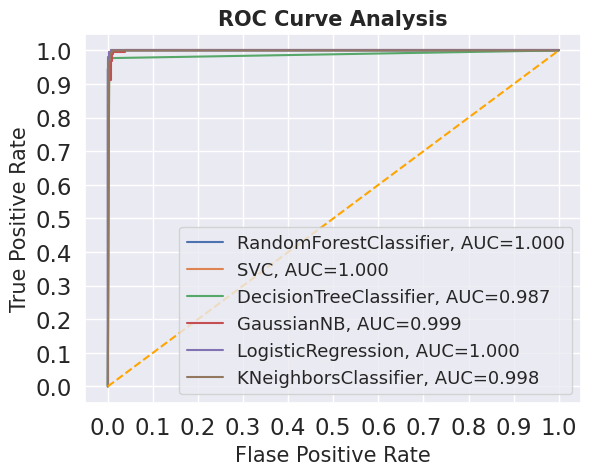

<Figure size 640x480 with 0 Axes>

In [ ]:
#fig = plt.figure(figsize=(8,6))

for i in result_table.index:
    plt.plot(result_table.loc[i]['fpr'],
             result_table.loc[i]['tpr'],
             label="{}, AUC={:.3f}".format(i, result_table.loc[i]['auc']))

plt.plot([0,1], [0,1], color='orange', linestyle='--')

plt.xticks(np.arange(0.0, 1.1, step=0.1))
plt.xlabel("Flase Positive Rate", fontsize=15)

plt.yticks(np.arange(0.0, 1.1, step=0.1))
plt.ylabel("True Positive Rate", fontsize=15)

plt.title('ROC Curve Analysis', fontweight='bold', fontsize=15)
#ax = plt.axes()
#ax.set_facecolor("white")
plt.grid(True)

plt.legend(prop={'size':13}, loc='lower right')
plt.show()
plt.savefig('/content/drive/My Drive/HairDetection/ROCCRSHOGDerm.png', dpi=300, bbox_inches='tight')

In [ ]:
import keras
from keras.models import Sequential
#from keras.models import Model
from keras.layers import Dense, Conv2D, MaxPool2D , Flatten
from keras.preprocessing.image import ImageDataGenerator
import numpy as np
from sklearn.preprocessing import LabelEncoder

In [ ]:
from keras.preprocessing import image
#from keras.applications.vgg16 import VGG16
from keras.applications.resnet50 import ResNet50
from keras.layers import Input
#from keras.applications.vgg16 import preprocess_input
y_train = np.array(y_train)
y_test=np.array(y_test)
x_train=np.array(x_train)
x_test=np.array(x_test)
#image_input=Input(shape=(x_train.shape[1],))
#image_input=input_shape=(x_train.shape[1],)
#image_input = np.expand_dims(image_input, axis=0)
#resnetModel = ResNet50(input_tensor=image_input,weights='imagenet', include_top=False)
#resnetModel = ResNet50(weights='imagenet', include_top=False)
#print(x_train.shape[1])

In [ ]:
#from keras.models import Sequential
y_train = np.array(y_train)
y_test=np.array(y_test)
x_train=np.array(x_train)
x_test=np.array(x_test)

encoder = LabelEncoder()
encoder.fit(y_train)
encoded_Ytrain = encoder.transform(y_train)

encoder.fit(y_test)
encoded_Ytest = encoder.transform(y_test)



# create model
NNmodel = Sequential()
NNmodel.add(Dense(4, input_shape=(x_train.shape[1],), activation='relu'))
NNmodel.add(Dense(4, activation='relu'))
NNmodel.add(Dense(4, activation='relu'))
#model.add(Dense(4, activation='relu'))
#model.add(Dense(2, activation='relu'))

NNmodel.add(Dense(1, activation='sigmoid'))
# Compile model
#model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
# Fit the model

NNmodel.summary()
# evaluate the model
#scores = model.evaluate(X, Y, verbose=0)
#print("%s: %.2f%%" % (model.metrics_names[1], scores[1]*100))

# serialize model to JSON
#model_json = model.to_json()
#with open("model.json", "w") as json_file:
#    json_file.write(model_json)
# serialize weights to HDF5


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 4)                 20        
                                                                 
 dense_1 (Dense)             (None, 4)                 20        
                                                                 
 dense_2 (Dense)             (None, 4)                 20        
                                                                 
 dense_3 (Dense)             (None, 1)                 5         
                                                                 
Total params: 65 (260.00 Byte)
Trainable params: 65 (260.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [ ]:
NNmodel.compile(optimizer='adam',loss='binary_crossentropy', metrics=['accuracy'])
history=NNmodel.fit(x_train, encoded_Ytrain,verbose=1, epochs=100, batch_size=64,validation_data=(x_test,encoded_Ytest))

Epoch 1/100
20/20 [==============================] - 2s 16ms/step - loss: 0.6170 - accuracy: 0.7039 - val_loss: 0.6102 - val_accuracy: 0.7269
Epoch 2/100
20/20 [==============================] - 0s 5ms/step - loss: 0.5933 - accuracy: 0.7371 - val_loss: 0.5860 - val_accuracy: 0.7343
Epoch 3/100
20/20 [==============================] - 0s 4ms/step - loss: 0.5665 - accuracy: 0.7641 - val_loss: 0.5586 - val_accuracy: 0.7601
Epoch 4/100
20/20 [==============================] - 0s 4ms/step - loss: 0.5357 - accuracy: 0.7878 - val_loss: 0.5270 - val_accuracy: 0.7841
Epoch 5/100
20/20 [==============================] - 0s 5ms/step - loss: 0.5014 - accuracy: 0.8108 - val_loss: 0.4925 - val_accuracy: 0.8118
Epoch 6/100
20/20 [==============================] - 0s 5ms/step - loss: 0.4655 - accuracy: 0.8646 - val_loss: 0.4550 - val_accuracy: 0.8911
Epoch 7/100
20/20 [==============================] - 0s 6ms/step - loss: 0.4267 - accuracy: 0.8979 - val_loss: 0.4154 - val_accuracy: 0.9096
Epoch 8/100


In [ ]:
#keras.saving.save_model(NNmodel,"/content/drive/My Drive/HairDetection/DLDerm_modelNN.h5")
NNmodel.save("/content/drive/My Drive/HairDetection/CRSHOGDerm_modelNN.keras")

In [ ]:
#loaded_model=model.load_weights("/content/drive/My Drive/EmotionDetection/text_modelNN.h5")

# evaluate loaded model on test data
#model.compile(loss='binary_crossentropy', optimizer='rmsprop', metrics=['accuracy'])
traintaccuracy=NNmodel.evaluate(x_train,encoded_Ytrain)
print(traintaccuracy[1]*100)
testaccuracy = NNmodel.evaluate(x_test,encoded_Ytest)
print(testaccuracy[1]*100)

predictions = (NNmodel.predict(x_test) > 0.5).astype("int32")

40/40 [==============================] - 0s 8ms/step - loss: 0.0131 - accuracy: 0.9960
99.60411787033081
17/17 [==============================] - 0s 5ms/step - loss: 0.0102 - accuracy: 0.9982
99.81549978256226
17/17 [==============================] - 0s 5ms/step


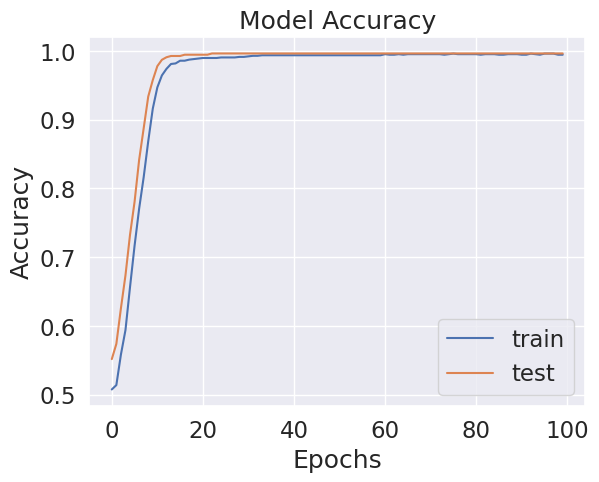

In [ ]:
import matplotlib.pyplot as plt1
#fig = plt1.figure(figsize=(8,6))
#plt.subplot(2,1,1)
plt1.plot(history.history['accuracy'])
plt1.plot(history.history['val_accuracy'])
plt1.title('Model Accuracy')
plt1.ylabel('Accuracy')
plt1.xlabel('Epochs')
plt1.legend(['train', 'test'], loc='lower right')
plt1.grid(True)
fig.set_facecolor('white')
#plt.Axes.set_facecolor(self='',color='# eafff5')
plt1.show()

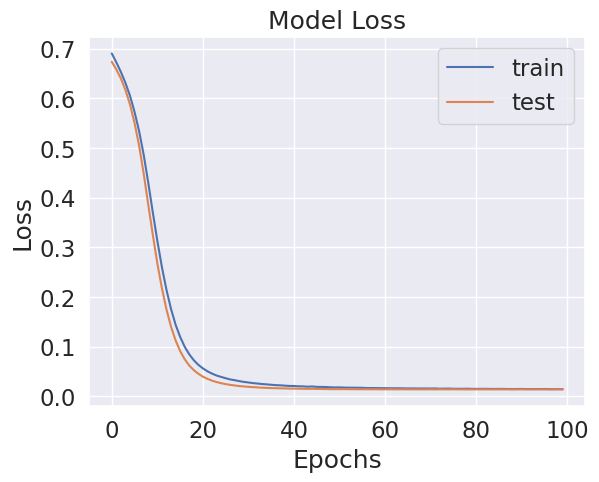

In [ ]:
#plt.subplot(2,1,1)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epochs')
plt.legend(['train', 'test'], loc='upper right')
plt.grid(True)
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy
import sklearn.metrics

#print(predictions)
print(classification_report(encoded_Ytest, predictions,digits=4))
#encoder.fit(y_pred_ANN)
#encoded_y_pred_ANN = encoder.transform(y_pred_ANN)
#print(encoded_y_pred_ANN)
#r = sklearn.metrics.confusion_matrix(encoded_Ytest, y_pred_ANN)
#print(r)

              precision    recall  f1-score   support

           0     0.9969    0.9969    0.9969       323
           1     0.9954    0.9954    0.9954       219

    accuracy                         0.9963       542
   macro avg     0.9962    0.9962    0.9962       542
weighted avg     0.9963    0.9963    0.9963       542



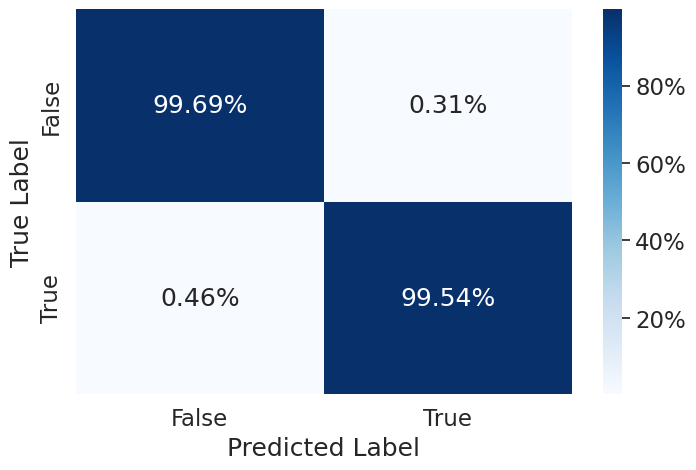

In [ ]:
blabels=[False,True]
cm_analysis(encoded_Ytest, predictions,"ANNCM.jpg",blabels,blabels)

In [ ]:
from sklearn.metrics import roc_curve, auc
fpr_keras, tpr_keras, thresholds_keras = roc_curve(encoded_Ytest, predictions)

In [ ]:
#from sklearn.metrics import auc
auc_keras = auc(fpr_keras, tpr_keras)

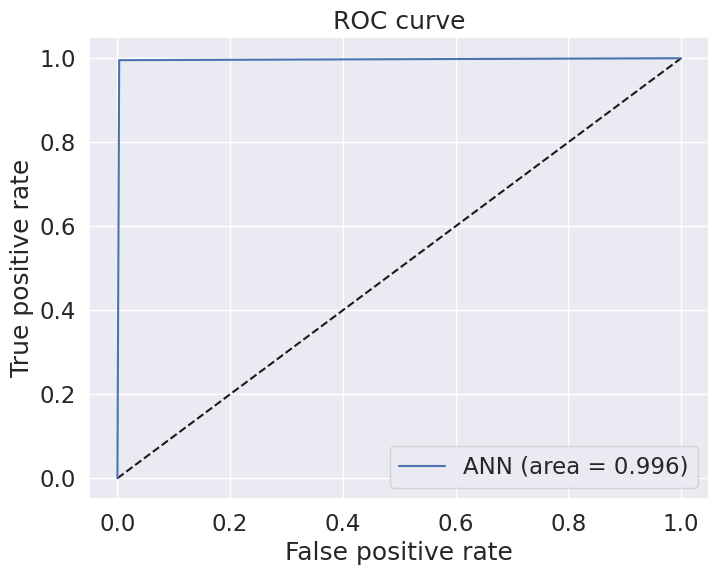

In [ ]:
fig = plt.figure(figsize=(8,6))
#plt.subplot(2,1,1)
#plt.figure(1)
plt.plot([0, 1], [0, 1], 'k--')
plt.plot(fpr_keras, tpr_keras, label='ANN (area = {:.3f})'.format(auc_keras))
#plt.plot(fpr_rf, tpr_rf, label='RF (area = {:.3f})'.format(auc_rf))
plt.xlabel('False positive rate')
#ax = plt.axes()
fig.set_facecolor("white")
plt.ylabel('True positive rate')
plt.title('ROC curve')
plt.legend(loc='best')
plt.grid(True)
plt.show()

In [ ]:
from sklearn import metrics
tn, fp, fn, tp = confusion_matrix(encoded_Ytest, predictions).ravel()

print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

# Sensitivity, hit rate, recall, or true positive rate
TPR = np.round(tp/(tp+fn),2)*100
# Specificity or true negative rate
TNR = np.round(tn/(tn+fp),2) * 100
# Precision or positive predictive value
PPV = tp/(tp+fp)
# Negative predictive value
NPV = tn/(tn+fn)
# Fall out or false positive rate
FPR = np.round(fp/(fp+tn),2)*100
# False negative rate
FNR = np.round(fn/(tp+fn),2)*100
# False discovery rate
FDR = fp/(tp+fp)

# Overall accuracy
ACC = (tp+tn)/(tp+fp+fn+tn)
print("True Positive Rate:", TPR)
print("True Negative Rate:", TNR)
print("False Positive Rate:", FPR)
print("False Negative Rate:", FNR)

True Negative: 322
False Positive: 1
False Negative: 1
True Positive: 218
True Positive Rate: 100.0
True Negative Rate: 100.0
False Positive Rate: 0.0
False Negative Rate: 0.0
